# Assignment 1: Data Profiling (EDA) Report
### Group 5 (T6) – E-Commerce Customer Reviews

| Name | Matric No. |
|---|---|
| HAZIQ NUR IMAN BIN MOHD RIZAL (Leader) | A210506 |
| MUHAMMAD RAZEEN REDHA BIN MOHAMAD RIDZUAN | A210729 |
| MOHAMMAD SADIQ BIN SAHROM | A209866 |
| WAN FAHIYM HUZEN BIN WAN HAFIZUDDIN | A209886 |

**How to run:** install the libraries with `pip install -r requirements.txt`, make sure the CSV file is inside the `data/` folder, then open this notebook and click **Kernel → Restart & Run All**.

## 1. Scenario

An online retail company receives thousands of customer reviews every day and wants to automatically classify customer complaints by product category and sentiment, so it knows which products to improve first. Real review data fits this assignment because it has missing text, duplicates, inconsistent category labels, outliers, and personal details written inside the reviews.

**Questions:** (1) Is the data complete and clean enough to label each review with a product category and a sentiment? (2) What problems must be fixed before building a classifier? (3) Are there PII or bias risks?

## 2. Data Source

- **Dataset:** Women's E-Commerce Clothing Reviews (Kaggle)
- **URL:** https://www.kaggle.com/datasets/nicapotato/womens-ecommerce-clothing-reviews
- **How we got it:** downloaded the CSV file from Kaggle and saved it as `data/womens_clothing_ecommerce_reviews.csv`.
- **Size:** 23,486 reviews and 11 columns. The reviews are real, from an online women's clothing store. Customer names and the store name were removed by the publisher.

Main columns: `Review Text` (the review), `Rating` (1–5 stars), `Recommended IND` (1 = recommends the product), `Age`, `Positive Feedback Count` (helpful votes), and the product category columns `Division Name`, `Department Name`, `Class Name`.

## 3. Data Profiling and Issue Handling

### 3.1 First look at the data

In [1]:
import html
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/womens_clothing_ecommerce_reviews.csv")
print("Shape:", df.shape)
df.head()

Shape: (23486, 11)


,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comfortable,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,"Love this dress! it's sooo pretty. i happened to find it in a store, and i'm glad i did bc i never would have ordered it online bc it's petite. i bought a petite and am 5'8"". i love the length on me- hits just a little below the knee. would definitely be a true midi on someone who is truly petite.",5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,"I had such high hopes for this dress and really wanted it to work for me. i initially ordered the petite small (my usual size) but i found this to be outrageously small. so small in fact that i could not zip it up! i reordered it in petite medium, which was just ok. overall, the top half was comfortable and fit nicely, but the bottom half had a very tight under layer and several somewhat cheap (net) over layers. imo, a major design flaw was the net over layer sewn directly into the zipper - it c",3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, flirty, and fabulous! every time i wear it, i get nothing but great compliments!",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to the adjustable front tie. it is the perfect length to wear with leggings and it is sleeveless so it pairs well with any cardigan. love this shirt!!!,5,1,6,General,Tops,Blouses


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Unnamed: 0               23486 non-null  int64
 1   Clothing ID              23486 non-null  int64
 2   Age                      23486 non-null  int64
 3   Title                    19676 non-null  str  
 4   Review Text              22641 non-null  str  
 5   Rating                   23486 non-null  int64
 6   Recommended IND          23486 non-null  int64
 7   Positive Feedback Count  23486 non-null  int64
 8   Division Name            23472 non-null  str  
 9   Department Name          23472 non-null  str  
 10  Class Name               23472 non-null  str  
dtypes: int64(6), str(5)
memory usage: 2.0 MB


In [3]:
df.describe()

,Unnamed: 0,Clothing ID,Age,Rating,Recommended IND,Positive Feedback Count
count,23486.000000,23486.000000,23486.000000,23486.000000,23486.000000,23486.000000
mean,11742.500000,918.118709,43.198544,4.196032,0.822362,2.535936
std,6779.968547,203.298980,12.279544,1.110031,0.382216,5.702202
min,0.000000,0.000000,18.000000,1.000000,0.000000,0.000000
25%,5871.250000,861.000000,34.000000,4.000000,1.000000,0.000000
50%,11742.500000,936.000000,41.000000,5.000000,1.000000,1.000000
75%,17613.750000,1078.000000,52.000000,5.000000,1.000000,3.000000
max,23485.000000,1205.000000,99.000000,5.000000,1.000000,122.000000


From the first look:
- `Unnamed: 0` is just the row number, so it is not useful.
- `Clothing ID` is stored as a number but it is an ID.
- `Title`, `Review Text` and the three category columns have missing values (fewer than 23,486 non-null).
- `Age` goes up to 99 and `Positive Feedback Count` goes up to 122, while its median is only 1. These need an outlier check.

### 3.2 Missing values

In [4]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({"missing": missing, "percent": missing_pct})

,missing,percent
Unnamed: 0,0,0.00
Clothing ID,0,0.00
Age,0,0.00
Title,3810,16.22
Review Text,845,3.60
Rating,0,0.00
Recommended IND,0,0.00
Positive Feedback Count,0,0.00
Division Name,14,0.06
Department Name,14,0.06


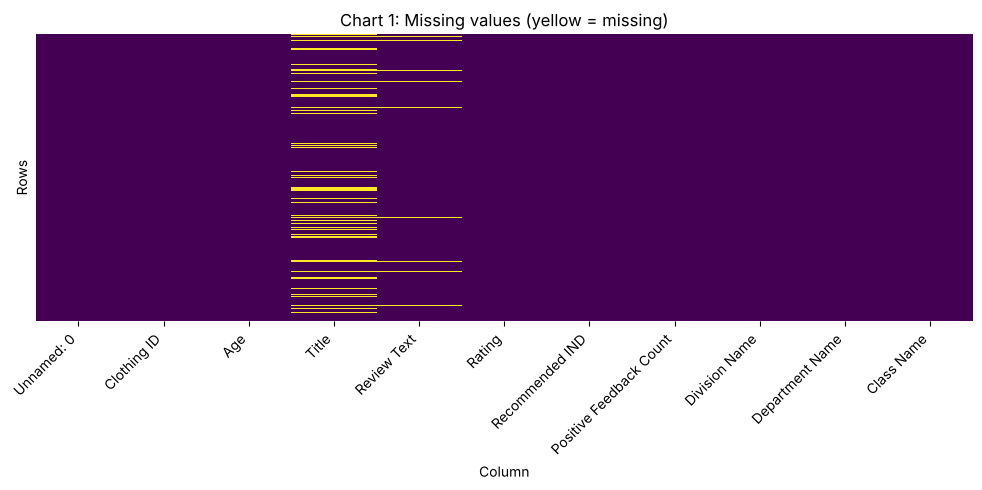

In [5]:
# Chart 1: missing-value heatmap
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Chart 1: Missing values (yellow = missing)")
plt.xlabel("Column")
plt.ylabel("Rows")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**What we found:**
- `Title`: 3,810 missing (16.2%)
- `Review Text`: 845 missing (3.6%)
- `Division Name`, `Department Name`, `Class Name`: 14 missing each (0.06%), always in the same rows

**What we did and why:**
- **Review Text → drop.** Our classifier needs the review text. A review with no text cannot be classified, and we should not make up text. 3.6% is a small loss.
- **Category columns → drop.** Product category is one of the labels we want to predict. We cannot guess it, and 14 rows is very small.
- **Title → fill with an empty string.** Many customers just skip the title, so it is normal, not an error. Dropping 16% of the data would waste good reviews.

In [6]:
rows_before = len(df)

df = df.dropna(subset=["Review Text"])
df = df.dropna(subset=["Division Name", "Department Name", "Class Name"])
df["Title"] = df["Title"].fillna("")

print("Rows removed:", rows_before - len(df))
print("Rows left:", len(df))
print("Missing values left:", df.isnull().sum().sum())

Rows removed: 858
Rows left: 22628
Missing values left: 0


### 3.3 Other quality issues

**(a) Useless column and duplicates**

In [7]:
df = df.drop(columns=["Unnamed: 0"])

print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("Rows left:", len(df))

Duplicate rows: 1
Rows left: 22627


We removed `Unnamed: 0` because it is only a row number. The original file had 21 fully duplicated rows, but most of them were empty reviews that were already dropped in 3.2. The duplicate left is the same review saved twice, so we keep only one copy. Otherwise the same opinion would be counted twice.

**(b) Wrong data types**

In [8]:
df["Clothing ID"] = df["Clothing ID"].astype(str)
df["Recommended IND"] = df["Recommended IND"].astype(bool)
df[["Clothing ID", "Recommended IND"]].dtypes

,0
Clothing ID,str
Recommended IND,bool


`Clothing ID` is an ID, not a number we should calculate with (its "average" means nothing), so we changed it to text. `Recommended IND` is only yes/no, so we changed it to boolean.

**(c) Inconsistent category labels**

In [9]:
print(df["Division Name"].value_counts())
print()
print(df["Class Name"].value_counts())

Division Name
General           13364
General Petite     7837
Initmates          1426
Name: count, dtype: int64

Class Name
Dresses           6145
Knits             4626
Blouses           2983
Sweaters          1380
Pants             1350
Jeans             1103
Fine gauge        1059
Skirts             903
Jackets            683
Lounge             669
Swim               332
Outerwear          319
Shorts             304
Sleep              214
Legwear            158
Intimates          147
Layering           132
Trend              118
Casual bottoms       1
Chemises             1
Name: count, dtype: int64


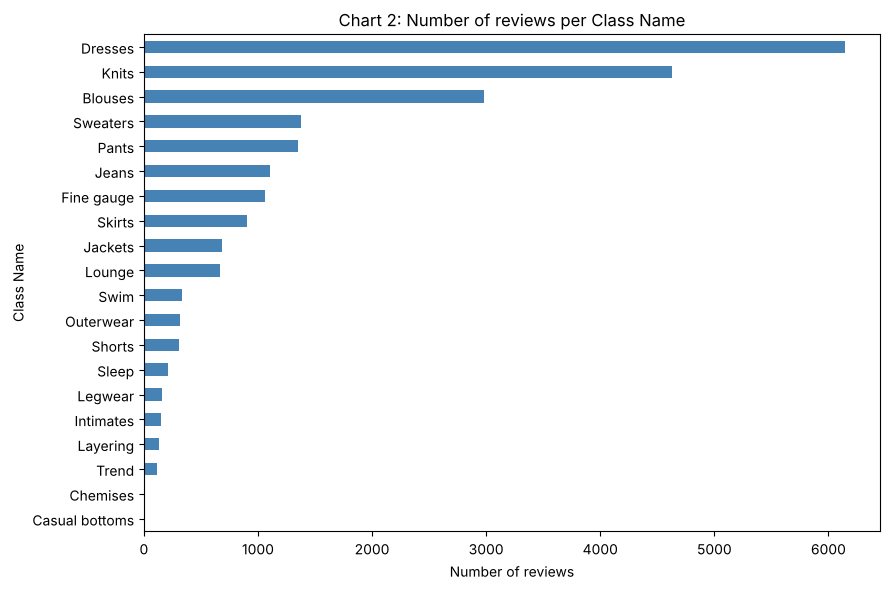

In [10]:
# Chart 2: number of reviews in each class
plt.figure(figsize=(9, 6))
df["Class Name"].value_counts().sort_values().plot(kind="barh", color="steelblue")
plt.title("Chart 2: Number of reviews per Class Name")
plt.xlabel("Number of reviews")
plt.ylabel("Class Name")
plt.tight_layout()
plt.show()

Problems:
- `Initmates` in `Division Name` is a spelling mistake for **Intimates**.
- `Casual bottoms` and `Chemises` have only 1 review each (bottom of Chart 2, the bars are too small to see). A model cannot learn a category from one example, so we merge them into similar classes: `Casual bottoms` → `Pants`, `Chemises` → `Intimates`.

In [11]:
df["Division Name"] = df["Division Name"].replace({"Initmates": "Intimates"})
df["Class Name"] = df["Class Name"].replace({"Casual bottoms": "Pants", "Chemises": "Intimates"})

print(df["Division Name"].value_counts())

Division Name
General           13364
General Petite     7837
Intimates          1426
Name: count, dtype: int64


**(d) Messy text format**

In [12]:
# Some reviews contain HTML codes like &#39; instead of an apostrophe
has_html = df["Review Text"].str.contains("&#39;|&amp;|&quot;")
print("Reviews with HTML codes:", has_html.sum())
print(df.loc[has_html, "Review Text"].iloc[0][:120])

Reviews with HTML codes: 58
I ordered this 3 months ago, and it finally came off back order. a huge disappointment. the fit wasn&#39;t so much the i


In [13]:
# Some text was encoded several times, so we decode it a few times
for i in range(5):
    df["Review Text"] = df["Review Text"].apply(html.unescape)

# Remove extra spaces and line breaks
df["Review Text"] = df["Review Text"].str.replace(r"\s+", " ", regex=True).str.strip()

print("Reviews with HTML codes now:", df["Review Text"].str.contains("&#39;|&amp;|&quot;").sum())

Reviews with HTML codes now: 0


Some reviews had HTML codes such as `&#39;` instead of `'`, and extra spaces or line breaks. These would confuse a text classifier, so we converted the codes back to normal characters and removed the extra spaces.

**(e) Rating and Recommended do not agree**

In [14]:
pd.crosstab(df["Rating"], df["Recommended IND"])

Recommended IND,False,True
Rating,,
1,806,15
2,1455,94
3,1653,1170
4,164,4744
5,23,12503


In [15]:
conflict = ((df["Rating"] <= 2) & (df["Recommended IND"] == True)) | \
           ((df["Rating"] == 5) & (df["Recommended IND"] == False))
df["label_conflict"] = conflict
print("Reviews where rating and recommendation disagree:", conflict.sum())

Reviews where rating and recommendation disagree: 132


Some customers gave 1–2 stars but still recommend the product, or gave 5 stars but do not recommend it. This does not make sense, and it may be a mistake or a mixed opinion. We **kept** these rows because we do not know which field is wrong and the review text is still useful, but we **flagged** them in a new column `label_conflict`. For sentiment we will use `Rating`.

### 3.4 Outliers

In [16]:
def count_iqr_outliers(column):
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n = ((df[column] < lower) | (df[column] > upper)).sum()
    print(f"{column}: lower = {lower}, upper = {upper}, outliers = {n}")

count_iqr_outliers("Age")
count_iqr_outliers("Positive Feedback Count")

Age: lower = 7.0, upper = 79.0, outliers = 108
Positive Feedback Count: lower = -4.5, upper = 7.5, outliers = 2147


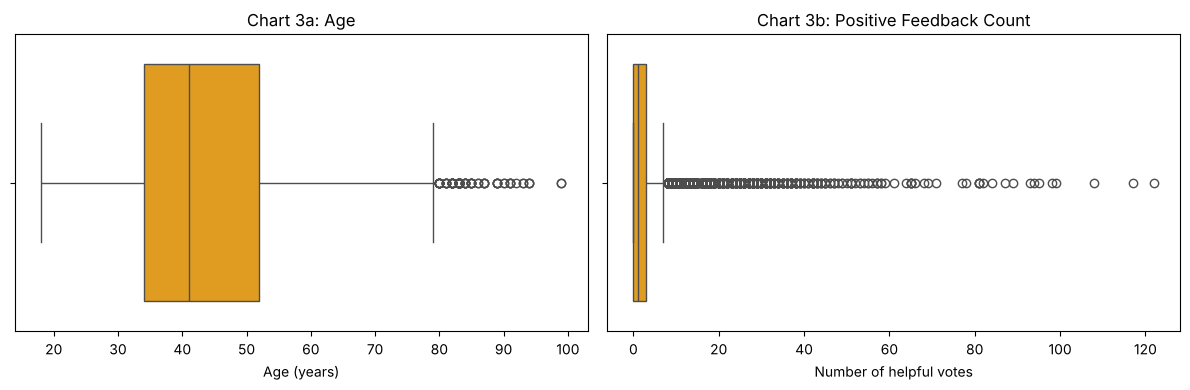

In [17]:
# Chart 3: boxplots for Age and Positive Feedback Count
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df["Age"], ax=axes[0], color="orange")
axes[0].set_title("Chart 3a: Age")
axes[0].set_xlabel("Age (years)")
sns.boxplot(x=df["Positive Feedback Count"], ax=axes[1], color="orange")
axes[1].set_title("Chart 3b: Positive Feedback Count")
axes[1].set_xlabel("Number of helpful votes")
plt.tight_layout()
plt.show()

We used the **IQR method** and **boxplots** to find outliers.

- **Age – kept.** About 100 reviewers are older than 79, with a few up to 99. Older customers are real, and removing them would make the data unfair to older shoppers. Ages like 99 might be a default value in a form, but we cannot prove it. Age is also not used to classify complaints.
- **Positive Feedback Count – kept, plus a capped copy.** Most reviews get 0–3 helpful votes, so the IQR method marks over 2,000 reviews as outliers even though they are normal. Reviews with many votes are real and are actually the most useful ones. We keep the original values and make a capped copy at the 99th percentile (`pfc_capped`), so a few very large values do not dominate if we use this column in a model later.

In [18]:
cap = df["Positive Feedback Count"].quantile(0.99)
df["pfc_capped"] = df["Positive Feedback Count"].clip(upper=cap)
print("Cap value:", cap)

Cap value: 27.0


## 4. Exploratory (Diagnostic) Charts

Charts 1–3 above show the missing values, category problems and outliers. Chart 4 checks whether the groups are balanced.

sentiment
Positive    0.770
Neutral     0.125
Negative    0.105
Name: proportion, dtype: float64


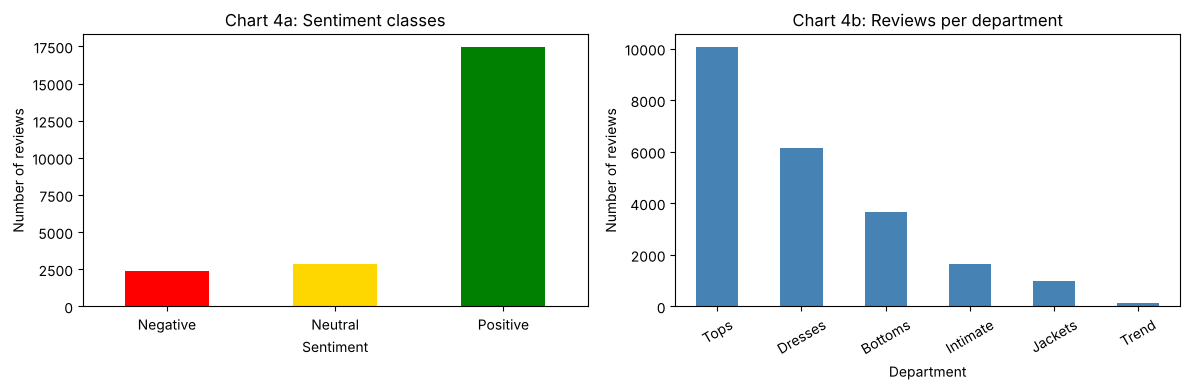

In [19]:
# Sentiment label from Rating: 1-2 = Negative (complaint), 3 = Neutral, 4-5 = Positive
df["sentiment"] = pd.cut(df["Rating"], bins=[0, 2, 3, 5], labels=["Negative", "Neutral", "Positive"])

# Chart 4: group balance
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["sentiment"].value_counts().reindex(["Negative", "Neutral", "Positive"]).plot(
    kind="bar", ax=axes[0], color=["red", "gold", "green"])
axes[0].set_title("Chart 4a: Sentiment classes")
axes[0].set_xlabel("Sentiment")
axes[0].set_ylabel("Number of reviews")
axes[0].tick_params(axis="x", rotation=0)

df["Department Name"].value_counts().plot(kind="bar", ax=axes[1], color="steelblue")
axes[1].set_title("Chart 4b: Reviews per department")
axes[1].set_xlabel("Department")
axes[1].set_ylabel("Number of reviews")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

print(df["sentiment"].value_counts(normalize=True).round(3))

- **Sentiment is very unbalanced.** About 77% of reviews are positive and only about 10% are complaints. A model could simply predict "Positive" every time and still look 77% accurate.
- **Departments are unbalanced.** Tops and Dresses have most of the reviews, while `Trend` has only about 120.

## 5. PII and Bias Risks

In [20]:
# Rough check: how many reviews mention body weight?
mentions_weight = df["Review Text"].str.contains("lbs|pounds", case=False)
print("Reviews mentioning weight (approx.):", mentions_weight.sum())
print(df.loc[mentions_weight, "Review Text"].iloc[0][:150])

Reviews mentioning weight (approx.): 2179
I'm 5"5' and 125 lbs. i ordered the s petite to make sure the length wasn't too long. i typically wear an xs regular in retailer dresses. if you're le


**PII risks**
- No names, emails or phone numbers are in the data (removed by the publisher).
- `Review Text`: many customers write their height, weight or body size. This is sensitive personal information. We would mask these details before sharing the data or sending it to another system. (The count above is only a rough estimate.)
- `Age` + `Clothing ID`: together they could help identify a person if combined with order records. We would use age groups (e.g. 25–34) instead of exact age, and not share the exact age.

**Bias risks**
- **Unbalanced sentiment:** complaints are only about 10%. We would use a stratified train/test split, give the complaint class more weight, and measure recall/F1 instead of accuracy.
- **Unbalanced departments:** small departments like `Trend` will be learned poorly. We would check results per department.
- **Self-selection bias:** only customers who chose to write a review are included, and most of them are happy customers.
- **Population bias:** the data is from one US clothing store, in English, for women's clothing only. It may not represent Malaysian online shoppers who write in Malay or Manglish.

## 6. Conclusion

In [21]:
df.to_csv("data/cleaned_reviews.csv", index=False)
print("Original rows: 23486")
print("Cleaned rows:", len(df))
print("Kept:", round(len(df) / 23486 * 100, 1), "%")

Original rows: 23486
Cleaned rows: 22627
Kept: 96.3 %


**Is the data fit for the scenario?** Yes, with some limitations. After cleaning we kept about 96% of the reviews. Every review now has text, a product category and a rating, so we can label it with a category and a sentiment and use it to train a complaint classifier.

**Limitations that remain:**
1. Complaints are only about 10% of the data, so the model needs class balancing.
2. Some categories (e.g. `Trend`) are small, and `Trend` is not a clear product type.
3. Some reviews have rating and recommendation that disagree, so the sentiment labels are not perfect.
4. Reviews contain body measurements (PII) that must be masked before sharing.
5. The data is from one US store in English, so results may not apply directly to Malaysian e-commerce.
6. The data tells us which product a complaint is about, but not the type of problem (size, quality, delivery). That would need extra labelling.